# RÚT TRÍCH ĐẶC TRƯNG RFM VÀ CHUẨN BỊ TẬP DỮ LIỆU HUẤN LUYỆN
## (RFM Feature Engineering & Data Splitting)
**Đề tài:** Phân khúc khách hàng bằng RFM và hành vi mua hàng (Online Retail II)

Notebook này thực hiện chuyên biệt toàn bộ quy trình **Feature Engineering** bộ chỉ số RFM từ tập dữ liệu giao dịch sạch `data/data_clean.csv`:
1. **Recency (R - Độ gần đây):** Số ngày tính từ lần mua hàng gần nhất của khách hàng đến thời điểm chốt phân tích.
2. **Frequency (F - Tần suất):** Số lượng hóa đơn giao dịch độc lập của từng khách hàng.
3. **Monetary (M - Giá trị chi tiêu):** Tổng số tiền khách hàng đã thanh toán tích lũy.
4. **Phân tích phân phối & Xử lý độ lệch:** Đánh giá Skewness và áp dụng biến đổi Log `np.log1p`.
5. **Phân chia tập dữ liệu (Train 64% / Validation 16% / Test 20%):** Thực hiện phân chia trước khi chuẩn hóa.
6. **Chuẩn hóa thang đo (StandardScaler):** Fit scaler DUY NHẤT trên tập Train nhằm chống rò rỉ dữ liệu (**Data Leakage**).
7. **Lưu trữ các tập dữ liệu:** Xuất các file `data/rfm_data.csv`, `data/rfm_train.csv`, `data/rfm_val.csv`, `data/rfm_test.csv`.

In [10]:
import os
import sys
import datetime as dt
import warnings
warnings.filterwarnings('ignore')

# Tự động tìm và chuyển về thư mục gốc dự án
current = os.path.abspath(os.getcwd())
while current != os.path.dirname(current):
    if os.path.exists(os.path.join(current, 'data')) and os.path.exists(os.path.join(current, 'Source')):
        break
    current = os.path.dirname(current)

PROJECT_ROOT = current
os.chdir(PROJECT_ROOT)

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
print(f"✅ Môi trường sẵn sàng tại thư mục gốc: {os.getcwd()}")

✅ Môi trường sẵn sàng tại thư mục gốc: c:\Users\Quân\Desktop\ml_group


### 1. Nạp dữ liệu giao dịch sạch `data/data_clean.csv`
Dữ liệu đã qua bước làm sạch (EDA & Preprocessing), không còn giá trị thiếu (`CustomerID` rỗng), không còn đơn hoàn hủy âm tiền, và đã tính sẵn cột `TotalPrice`.

In [11]:
df_clean = pd.read_csv("data/data_clean.csv")
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

print(f"📊 Số lượng bản ghi giao dịch: {df_clean.shape[0]:,}")
print(f"👤 Số lượng khách hàng duy nhất: {df_clean['CustomerID'].nunique():,}")
print(f"📅 Khoảng thời gian: từ {df_clean['InvoiceDate'].min().strftime('%Y-%m-%d')} đến {df_clean['InvoiceDate'].max().strftime('%Y-%m-%d')}")
df_clean.head()

📊 Số lượng bản ghi giao dịch: 398,971
👤 Số lượng khách hàng duy nhất: 4,275
📅 Khoảng thời gian: từ 2009-12-01 đến 2010-12-09


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


### 2. Tính toán bộ chỉ số RFM (Recency, Frequency, Monetary)
- **Snapshot Date (Mốc thời gian chốt phân tích):** Chọn bằng ngày phát sinh giao dịch muộn nhất cộng thêm 1 ngày (`max(InvoiceDate) + 1 day`).
- **Recency:** $\text{Recency} = \text{Snapshot Date} - \max(\text{InvoiceDate})$ (tính bằng số ngày).
- **Frequency:** Đếm số lượng hóa đơn duy nhất (`InvoiceNo.nunique()`).
- **Monetary:** Tổng số tiền đã thanh toán (`TotalPrice.sum()`).

In [12]:
snapshot_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)
print(f"🕒 Snapshot Date chốt phân tích: {snapshot_date.strftime('%Y-%m-%d')}")

rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
}).reset_index()

rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

print(f"✅ Đã trích xuất RFM cho {rfm.shape[0]:,} khách hàng.")
rfm.head(10)

🕒 Snapshot Date chốt phân tích: 2010-12-10
✅ Đã trích xuất RFM cho 4,275 khách hàng.


,CustomerID,Recency,Frequency,Monetary
0,12346,165,11,372.86
1,12347,3,2,1323.32
2,12348,74,1,221.16
3,12349,43,2,2221.14
4,12351,11,1,300.93
5,12352,11,2,343.80
6,12353,44,1,317.76
7,12355,203,1,488.21
8,12356,16,3,3124.30
9,12357,24,1,11229.99


### 3. Khám phá phân phối thống kê & Độ lệch (Skewness)
Các chỉ số hành vi khách hàng trong thương mại điện tử thường có độ lệch phải (Positive Skewness) rất cao do một nhóm nhỏ khách hàng VIP mua sắm liên tục với giá trị cực lớn.

In [13]:
print("--- Thống kê mô tả bộ chỉ số RFM ---")
print(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))

print("\n--- Hệ số độ lệch Skewness ---")
print (rfm[["Recency", "Frequency", "Monetary"]].skew().round(3))


--- Thống kê mô tả bộ chỉ số RFM ---
       Recency  Frequency   Monetary
count   4275.0    4275.00    4275.00
mean      90.6       4.42    1942.87
std       96.4       7.90    8382.08
min        1.0       1.00       2.95
25%       18.0       1.00     305.28
50%       52.0       2.00     687.31
75%      136.0       5.00    1676.86
max      374.0     183.00  323860.53

--- Hệ số độ lệch Skewness ---
Recency       1.293
Frequency     9.942
Monetary     24.222
dtype: float64


### 4. Trực quan hóa phân phối gốc của RFM
Biểu đồ Histogram và Boxplot giúp nhận diện trực quan phân phối bất đối xứng và các điểm giá trị ngoại lai (outliers).

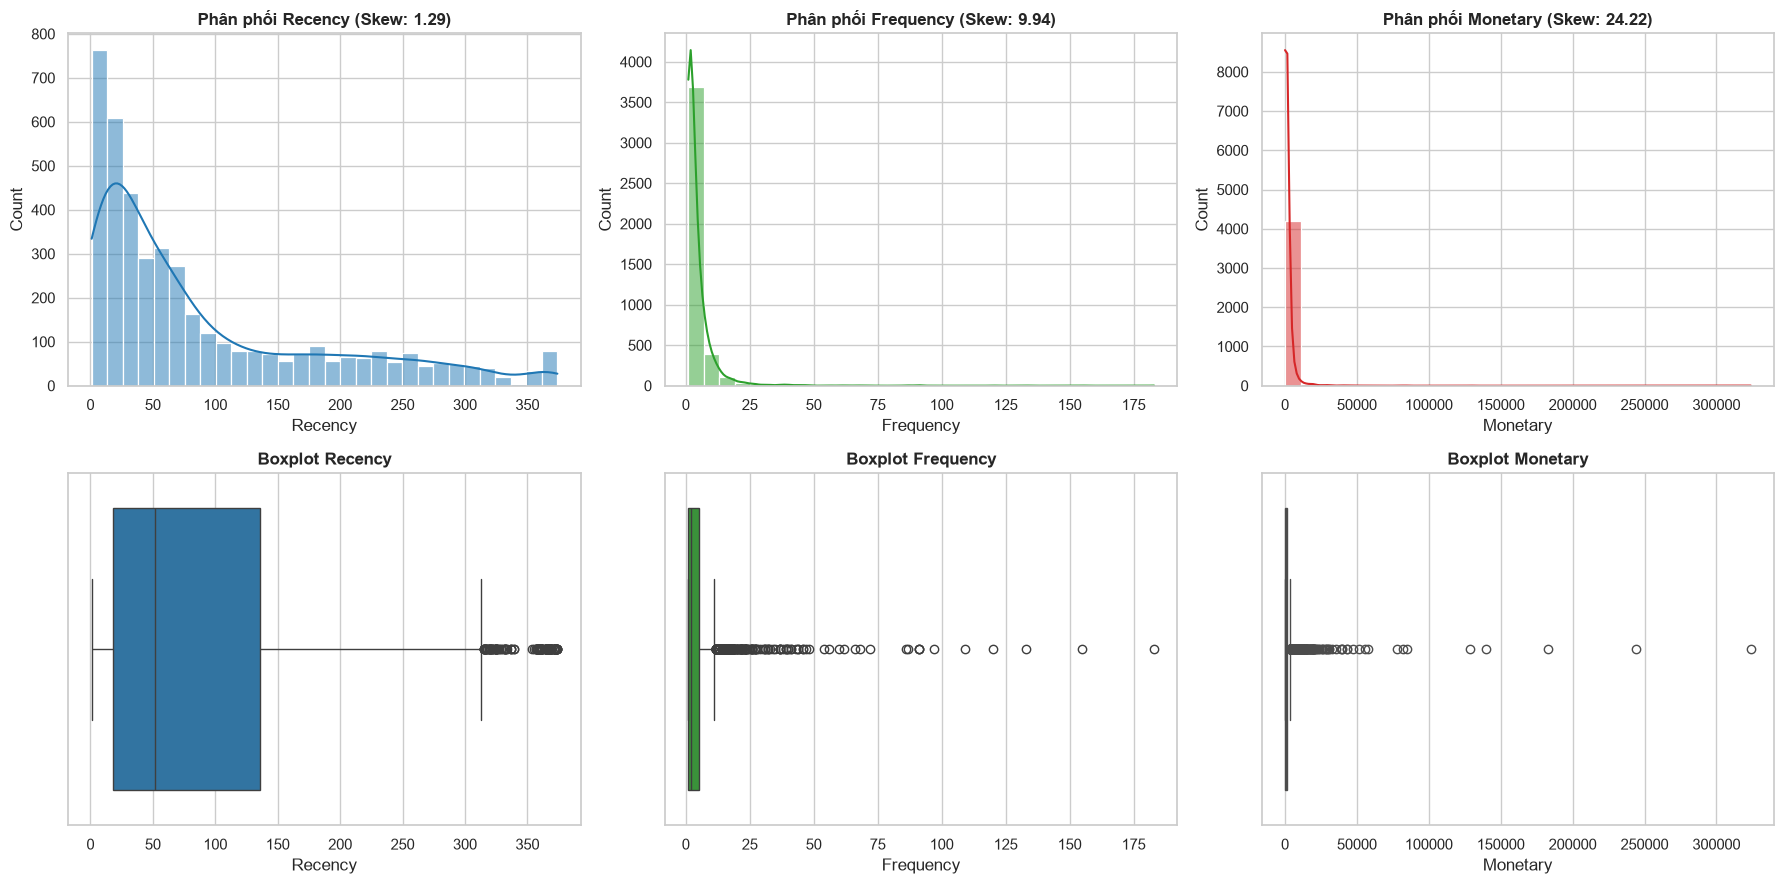

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))

features = ['Recency', 'Frequency', 'Monetary']
colors = ['#1f77b4', '#2ca02c', '#d62728']

for i, col in enumerate(features):
    # Histogram KDE
    sns.histplot(rfm[col], kde=True, ax=axes[0, i], color=colors[i], bins=30)
    axes[0, i].set_title(f"Phân phối {col} (Skew: {rfm[col].skew():.2f})", fontsize=12, fontweight='bold')
    
    # Boxplot
    sns.boxplot(x=rfm[col], ax=axes[1, i], color=colors[i])
    axes[1, i].set_title(f"Boxplot {col}", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### 5. Phân chia tập dữ liệu (Train / Validation / Test)
**Nguyên tắc chống rò rỉ dữ liệu (Data Leakage):**
- Chúng ta phân chia tập dữ liệu **trước** khi fit scaler chuẩn hóa thang đo.
- Tỷ lệ phân chia: **64% Train / 16% Validation / 20% Test** (sử dụng cố định `random_state=42`).

In [15]:
train_val_rfm, test_rfm = train_test_split(rfm, test_size=0.2, random_state=42)
train_rfm, val_rfm = train_test_split(train_val_rfm, test_size=0.2, random_state=42)

print(f"✅ Tập Huấn luyện (Train):      {train_rfm.shape[0]:,} khách hàng ({train_rfm.shape[0]/len(rfm)*100:.1f}%)")
print(f"✅ Tập Kiểm định (Validation):  {val_rfm.shape[0]:,} khách hàng ({val_rfm.shape[0]/len(rfm)*100:.1f}%)")
print(f"✅ Tập Kiểm thử (Test):         {test_rfm.shape[0]:,} khách hàng ({test_rfm.shape[0]/len(rfm)*100:.1f}%)")

✅ Tập Huấn luyện (Train):      2,736 khách hàng (64.0%)
✅ Tập Kiểm định (Validation):  684 khách hàng (16.0%)
✅ Tập Kiểm thử (Test):         855 khách hàng (20.0%)


### 6. Xử lý độ lệch (Log-Transform) & Chuẩn hóa (StandardScaler)
1. Áp dụng `np.log1p` trên từng tập dữ liệu để kéo các giá trị lệch về phân phối tiệm cận chuẩn.
2. Khởi tạo `StandardScaler` và gọi hàm `scaler.fit_transform()` **chỉ trên tập Train**.
3. Áp dụng `scaler.transform()` trên tập Validation và Test bằng thông số (Mean, Std) đã học từ tập Train.

In [16]:
# Biến đổi Log
X_train_log = np.log1p(train_rfm[["Recency", "Frequency", "Monetary"]])
X_val_log = np.log1p(val_rfm[["Recency", "Frequency", "Monetary"]])
X_test_log = np.log1p(test_rfm[["Recency", "Frequency", "Monetary"]])

print("--- Hệ số Skewness sau khi Log-Transform (Tập Train) ---")
print(X_train_log.skew().round(3))

# Chuẩn hóa thang đo StandardScaler (Fit duy nhất trên Train)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_log)
X_val_scaled = scaler.transform(X_val_log)
X_test_scaled = scaler.transform(X_test_log)

print("\n✅ StandardScaler Mean (Train):", scaler.mean_.round(3))
print("✅ StandardScaler Scale/Std (Train):", scaler.scale_.round(3))


--- Hệ số Skewness sau khi Log-Transform (Tập Train) ---
Recency     -0.439
Frequency    1.173
Monetary     0.309
dtype: float64

✅ StandardScaler Mean (Train): [3.871 1.368 6.593]
✅ StandardScaler Scale/Std (Train): [1.31  0.695 1.278]


### 7. Xuất và lưu trữ các tập dữ liệu RFM ra file CSV
Lưu vào thư mục `data/` để cung cấp đầu vào độc lập cho các notebook huấn luyện mô hình:
- `data/rfm_data.csv`: Bảng chỉ số RFM toàn bộ khách hàng.
- `data/rfm_train.csv`: Tập dữ liệu huấn luyện RFM (dành cho các notebook baseline).
- `data/rfm_val.csv`: Tập dữ liệu kiểm định tham số mô hình.
- `data/rfm_test.csv`: Tập dữ liệu kiểm thử cuối cùng.

In [17]:
rfm.to_csv("data/rfm_data.csv", index=False)
train_rfm.to_csv("data/rfm_train.csv", index=False)
val_rfm.to_csv("data/rfm_val.csv", index=False)
test_rfm.to_csv("data/rfm_test.csv", index=False)

print("💾 ĐÃ XUẤT CÁC FILE CSV THÀNH CÔNG:")
print(f"   - data/rfm_data.csv   ({rfm.shape[0]:,} dòng)")
print(f"   - data/rfm_train.csv  ({train_rfm.shape[0]:,} dòng)")
print(f"   - data/rfm_val.csv    ({val_rfm.shape[0]:,} dòng)")
print(f"   - data/rfm_test.csv   ({test_rfm.shape[0]:,} dòng)")

💾 ĐÃ XUẤT CÁC FILE CSV THÀNH CÔNG:
   - data/rfm_data.csv   (4,275 dòng)
   - data/rfm_train.csv  (2,736 dòng)
   - data/rfm_val.csv    (684 dòng)
   - data/rfm_test.csv   (855 dòng)


### 8. Trực quan hóa ma trận tương quan & Không gian RFM
Quan sát mối liên hệ giữa Recency, Frequency và Monetary sau biến đổi.

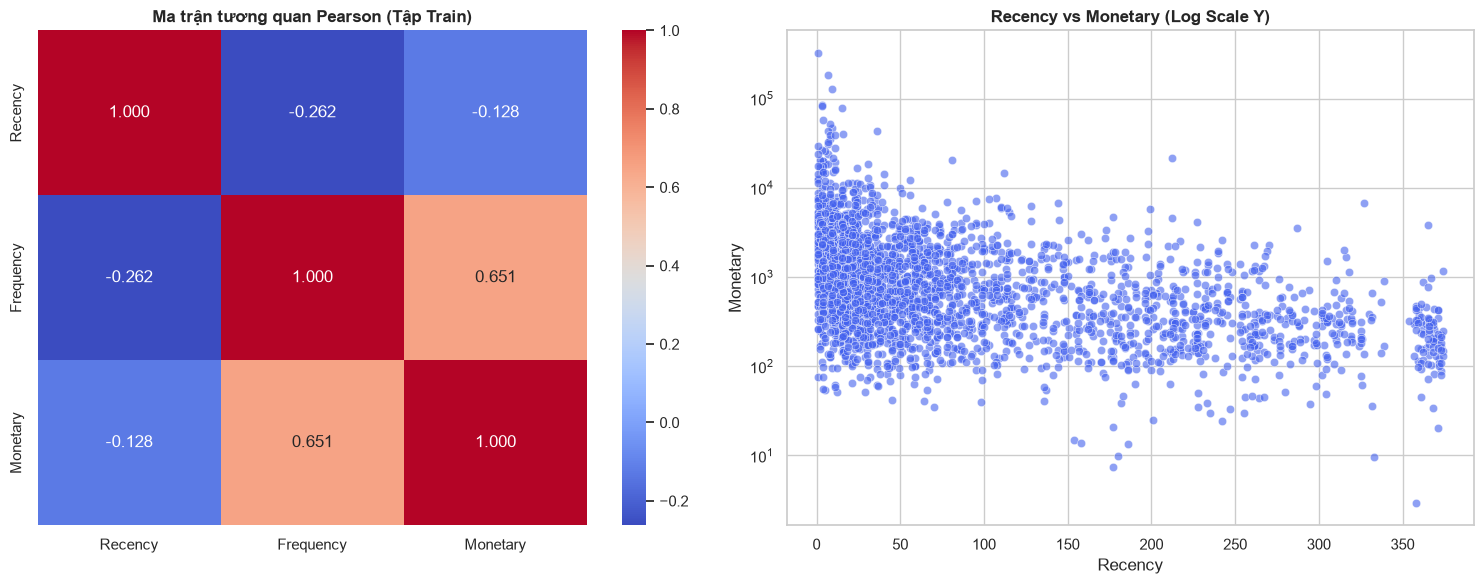

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Heatmap tương quan
corr = train_rfm[['Recency', 'Frequency', 'Monetary']].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".3f", ax=ax1, cbar=True)
ax1.set_title("Ma trận tương quan Pearson (Tập Train)", fontsize=12, fontweight='bold')

# Scatter Recency vs Monetary
sns.scatterplot(data=train_rfm, x="Recency", y="Monetary", alpha=0.6, ax=ax2, color="#4361ee")
ax2.set_yscale("log")
ax2.set_title("Recency vs Monetary (Log Scale Y)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

---
## TỔNG KẾT BƯỚC RÚT TRÍCH ĐẶC TRƯNG RFM

1. **Trích xuất hoàn tất:** Bộ chỉ số RFM được tính toán chính xác theo từng khách hàng (`CustomerID`).
2. **Chống Data Leakage:** Đã phân chia tập dữ liệu (Train 64% / Val 16% / Test 20%) trước khi chuẩn hóa; chuẩn hóa được fit duy nhất trên Train.
3. **Sẵn sàng huấn luyện:** Dữ liệu đã xuất ra `data/rfm_train.csv`.
4. **Bước tiếp theo:** Người dùng có thể mở các notebook baseline để huấn luyện mô hình:
   - `Source/notebook/KMeans_baseline.ipynb`
   - `Source/notebook/Hierarchical_baseline.ipynb`
   - `Source/notebook/DBSCAN_baseline.ipynb`